In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

In [3]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  str    
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(9), str(7)
memory usage: 2.0 MB


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df['User_Score'] = pd.to_numeric(df['User_Score'], errors='coerce')

In [6]:
df = df[df['Year_of_Release'].notna()]
df['Year_of_Release'] = df['Year_of_Release'].astype(int)

In [7]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
print(missing[missing > 0])

User_Score      54.632219
User_Count      54.632219
Critic_Score    51.471125
Critic_Count    51.471125
Rating          40.613982
Developer       39.775076
Publisher        0.194529
Name             0.012158
Genre            0.012158
dtype: float64


In [8]:
df['Developer'] = df['Developer'].fillna('Unknown')
df['Rating'] = df['Rating'].fillna('Unknown')
df['Publisher'] = df['Publisher'].fillna('Unknown')

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
top_10_games = df.sort_values(by='Global_Sales', ascending=False).head(10)

C:\Users\danic\AppData\Local\Temp\ipykernel_29080\1712116067.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


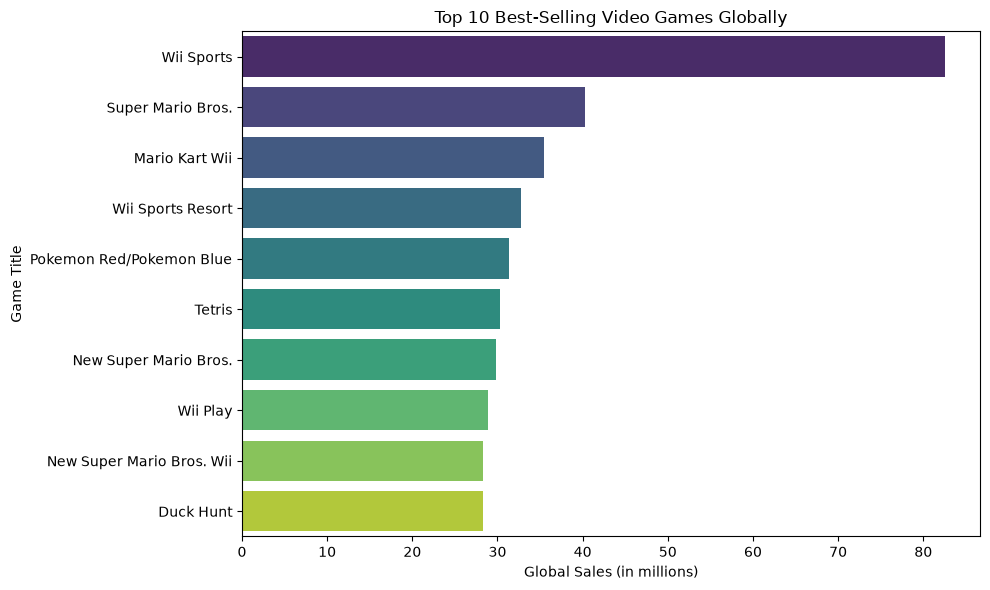

In [11]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_games,
    x='Global_Sales',
    y='Name',
    palette='viridis'
)

plt.title('Top 10 Best-Selling Video Games Globally')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Game Title')
plt.tight_layout()
plt.show()

In [12]:
# Group total global sales by year
sales_by_year = df.groupby('Year_of_Release')['Global_Sales'].sum().reset_index()

# Sort by year just in case
sales_by_year = sales_by_year.sort_values('Year_of_Release')

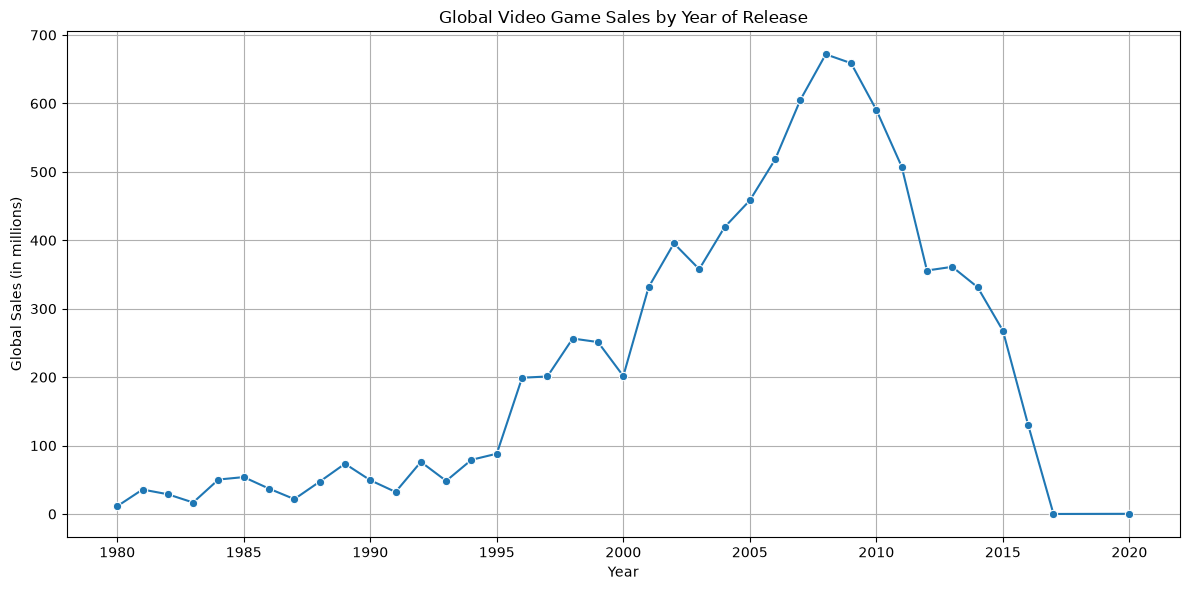

In [13]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=sales_by_year, x='Year_of_Release', y='Global_Sales', marker='o')
plt.title('Global Video Game Sales by Year of Release')
plt.xlabel('Year')
plt.ylabel('Global Sales (in millions)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# Group total global sales by platform
platform_sales = df.groupby('Platform')['Global_Sales'].sum().reset_index()

In [15]:
# Sort by sales in descending order and get top 10 platforms
top_platforms = platform_sales.sort_values('Global_Sales', ascending=False).head(10)

C:\Users\danic\AppData\Local\Temp\ipykernel_29080\219359548.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_platforms, x='Global_Sales', y='Platform', palette='cubehelix')


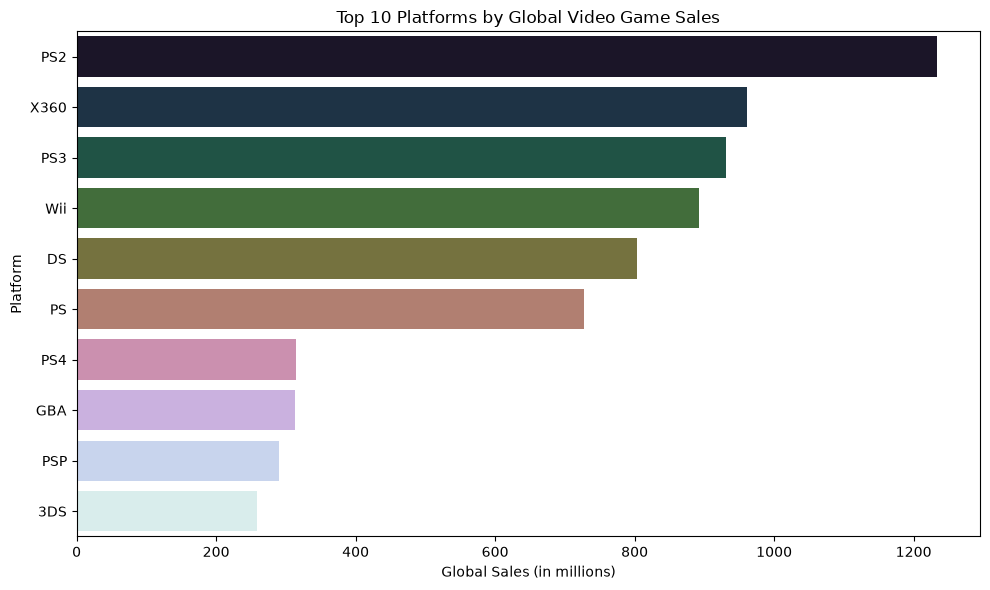

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(data=top_platforms, x='Global_Sales', y='Platform', palette='cubehelix')

plt.title('Top 10 Platforms by Global Video Game Sales')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Platform')
plt.tight_layout()
plt.show()

In [17]:
# Group total global sales by genre
genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()

In [18]:
# Sort genres by sales
genre_sales = genre_sales.sort_values('Global_Sales', ascending=False)


C:\Users\danic\AppData\Local\Temp\ipykernel_29080\355134028.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_sales, x='Global_Sales', y='Genre', palette='magma')


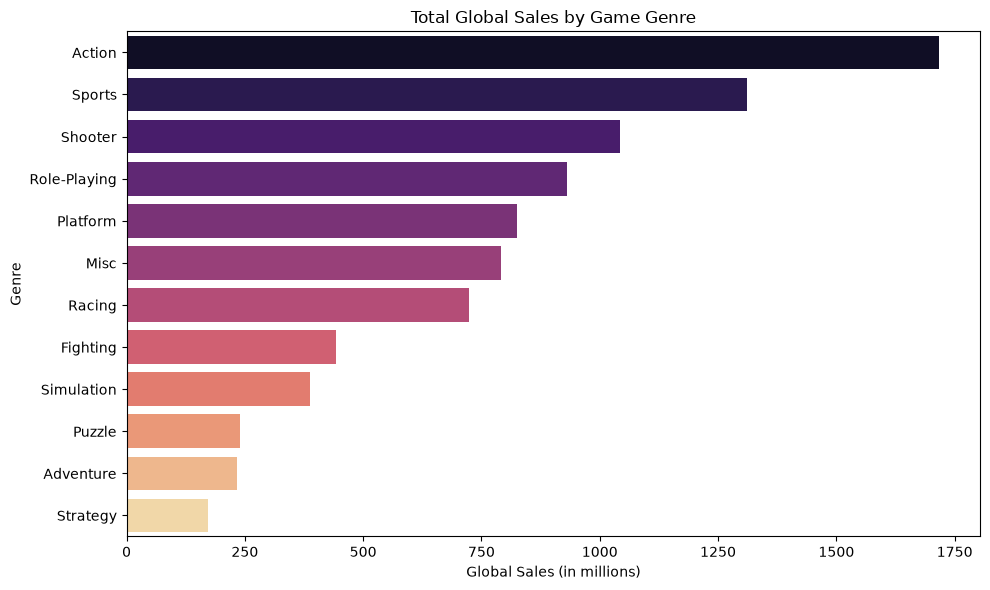

In [19]:
plt.figure(figsize=(10, 6))
sns.barplot(data=genre_sales, x='Global_Sales', y='Genre', palette='magma')

plt.title('Total Global Sales by Game Genre')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [20]:
# Group sales by genre and region
regional_sales = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales']].sum().reset_index()


In [21]:
# Reshape for grouped bar plot
regional_sales_melted = regional_sales.melt(id_vars='Genre', 
                                             value_vars=['NA_Sales', 'EU_Sales', 'JP_Sales'],
                                             var_name='Region', 
                                             value_name='Sales')

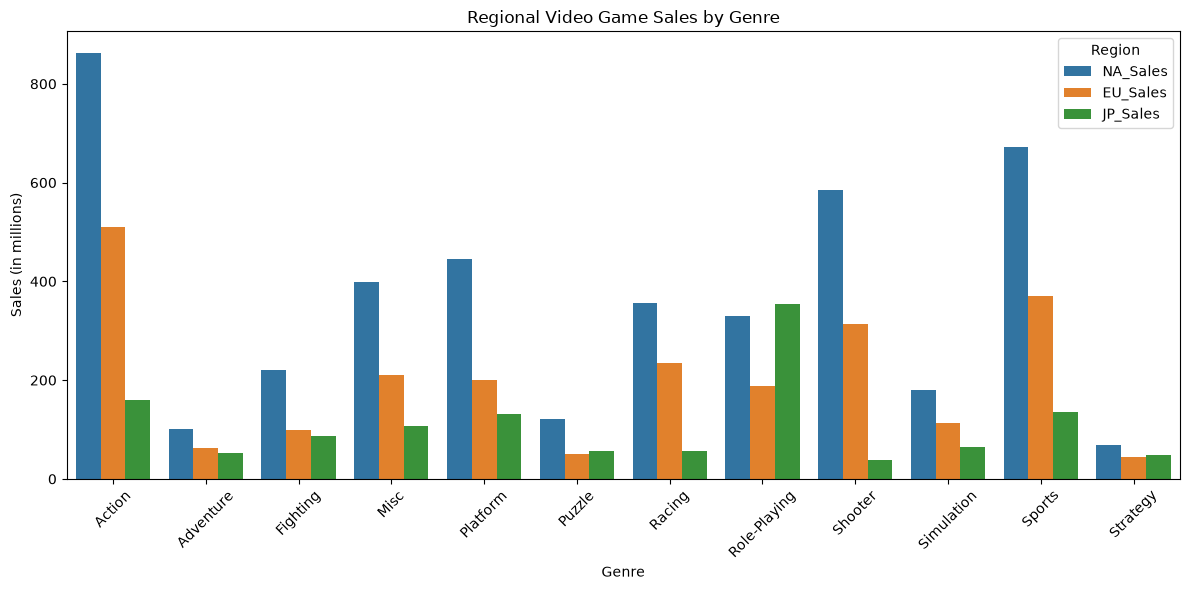

In [22]:
plt.figure(figsize=(12, 6))
sns.barplot(data=regional_sales_melted, x='Genre', y='Sales', hue='Region')

plt.title('Regional Video Game Sales by Genre')
plt.xlabel('Genre')
plt.ylabel('Sales (in millions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
# Drop rows with missing critic or user scores
score_data = df[['Critic_Score', 'User_Score']].dropna()

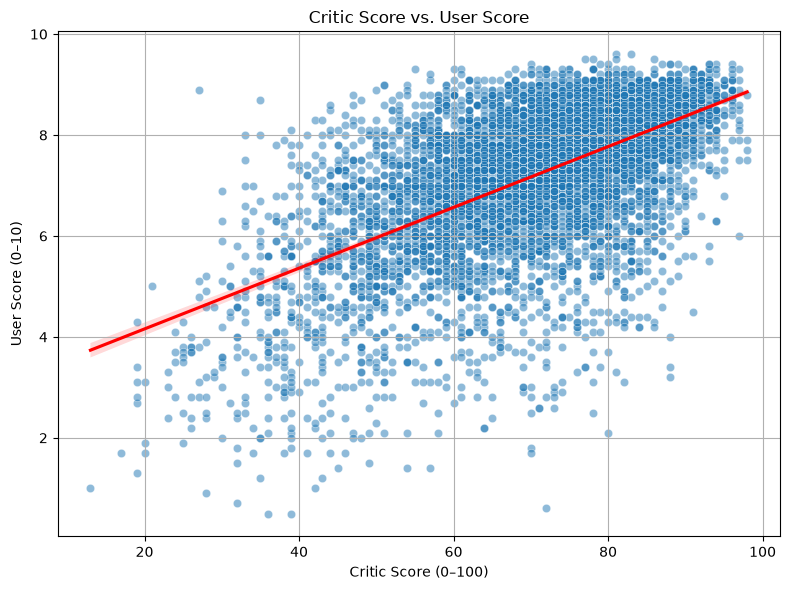

In [24]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=score_data, x='Critic_Score', y='User_Score', alpha=0.5)
sns.regplot(data=score_data, x='Critic_Score', y='User_Score', scatter=False, color='red')

plt.title('Critic Score vs. User Score')
plt.xlabel('Critic Score (0–100)')
plt.ylabel('User Score (0–10)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
# Filter data with both critic score and global sales
score_sales = df[['Critic_Score', 'Global_Sales']].dropna()


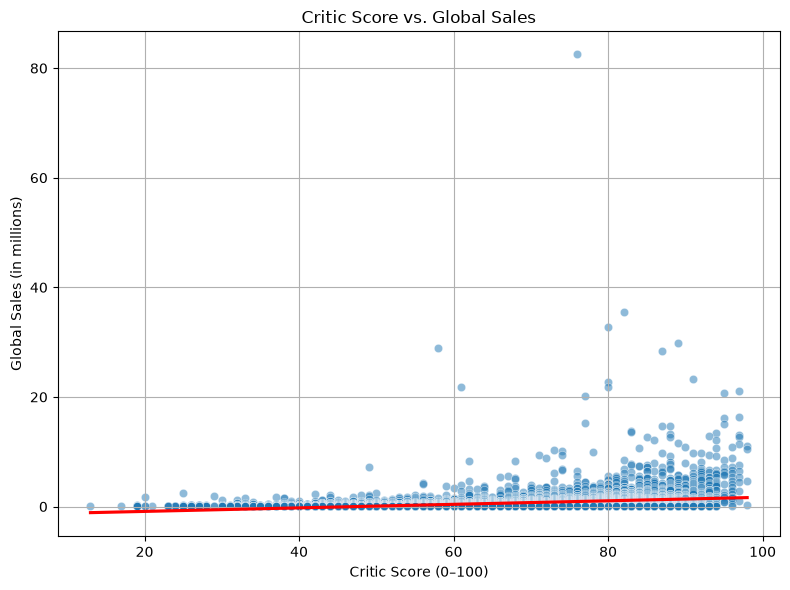

In [26]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=score_sales, x='Critic_Score', y='Global_Sales', alpha=0.5)
sns.regplot(data=score_sales, x='Critic_Score', y='Global_Sales', scatter=False, color='red')

plt.title('Critic Score vs. Global Sales')
plt.xlabel('Critic Score (0–100)')
plt.ylabel('Global Sales (in millions)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
rating_sales = df[['Rating', 'Global_Sales']].dropna()

C:\Users\danic\AppData\Local\Temp\ipykernel_29080\3607820323.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rating_sales, x='Rating', y='Global_Sales', palette='Set2')


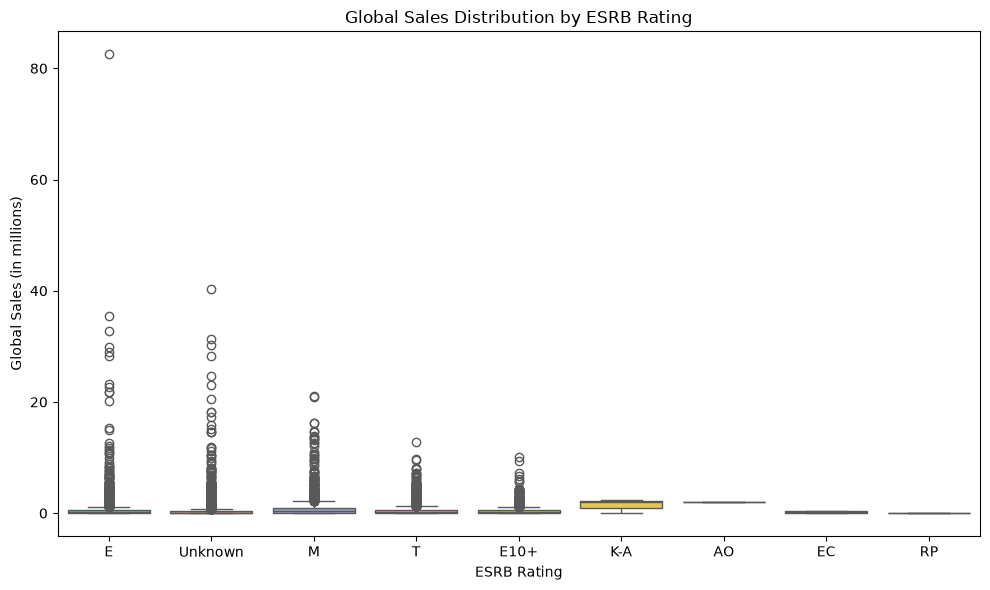

In [28]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=rating_sales, x='Rating', y='Global_Sales', palette='Set2')

plt.title('Global Sales Distribution by ESRB Rating')
plt.xlabel('ESRB Rating')
plt.ylabel('Global Sales (in millions)')
plt.tight_layout()
plt.show()

In [29]:
publisher_sales = df.groupby('Publisher')['Global_Sales'].sum().reset_index()

In [30]:
top_publishers = publisher_sales.sort_values(by='Global_Sales', ascending=False).head(10)

C:\Users\danic\AppData\Local\Temp\ipykernel_29080\1201101032.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_publishers, x='Global_Sales', y='Publisher', palette='pastel')


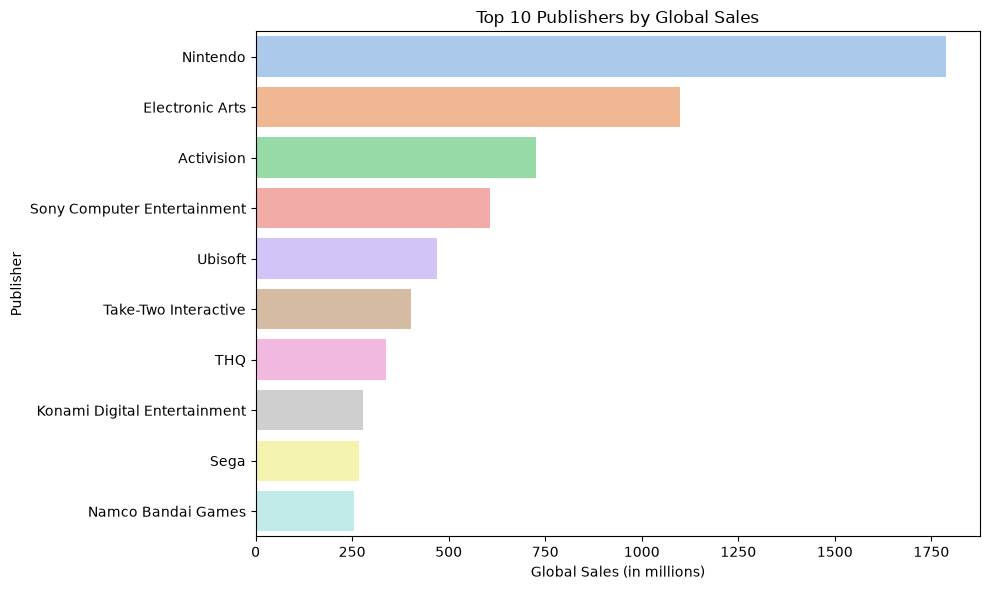

In [31]:
plt.figure(figsize=(10, 6))
sns.barplot(data=top_publishers, x='Global_Sales', y='Publisher', palette='pastel')

plt.title('Top 10 Publishers by Global Sales')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Publisher')
plt.tight_layout()
plt.show()

In [32]:
# Count number of games released per year
games_per_year = df['Year_of_Release'].value_counts().reset_index()
games_per_year.columns = ['Year', 'Game_Count']
games_per_year = games_per_year.sort_values('Year')

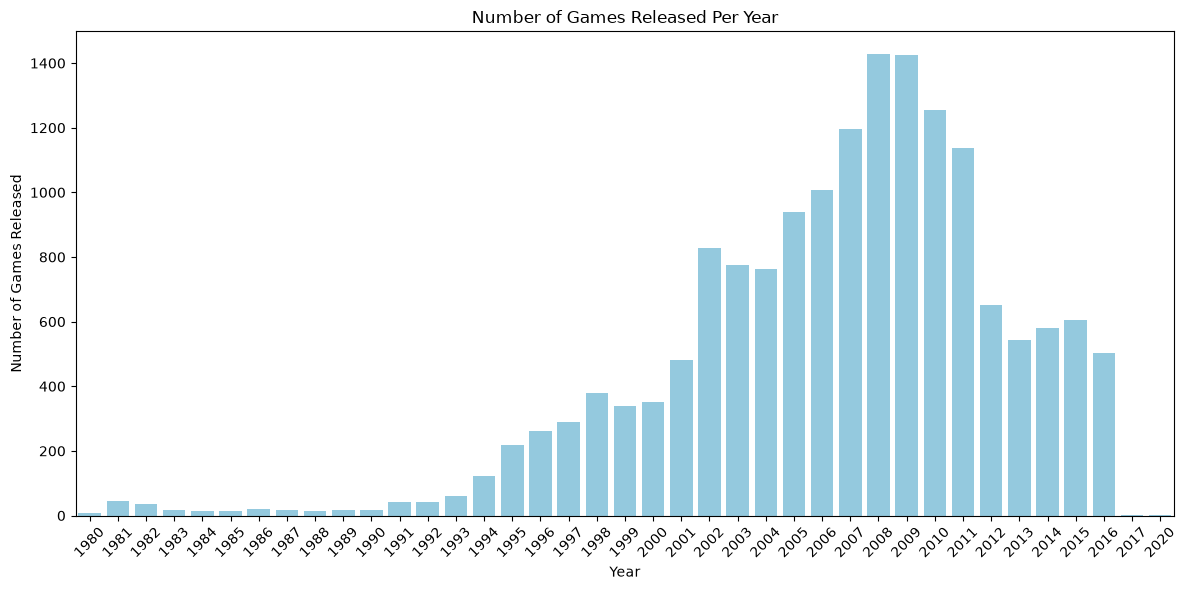

In [33]:
plt.figure(figsize=(12, 6))
sns.barplot(data=games_per_year, x='Year', y='Game_Count', color='skyblue')

plt.title('Number of Games Released Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Games Released')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()